# Pertemuan 10 — Praktikum 2: Naive Bayes dengan Data Dummy

Praktikum ini membangun model Naive Bayes pada data sintetis dua kelas. Model yang dibuat adalah **MultinomialNB** (untuk data diskrit) dan **GaussianNB** (untuk data kontinu) sebagai perbandingan.

Sumber: [Praktikum 2](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi/praktikum-2).

## 1. Import Library

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Langkah 1 — Buat Dataset Dummy

Dataset dibuat dengan `make_classification`. Hasilnya berupa nilai float yang kemudian diubah menjadi bilangan bulat tak negatif agar dapat dipakai oleh model Multinomial.

In [16]:
from sklearn.datasets import make_classification

# Membuat data dummy
X, y = make_classification(n_samples=30, n_features=2, n_classes=2,
                           n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# Ubah menjadi nilai diskrit tak negatif
X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print(X)
print(y)

[[ 37   9]
 [166 167]
 [131 125]
 [ 45  25]
 [199 158]
 [ 14   9]
 [113  48]
 [ 43  56]
 [106 107]
 [  1  12]
 [245 283]
 [ 23  44]
 [241 258]
 [150 158]
 [127 138]
 [144 153]
 [156  37]
 [113 154]
 [118  74]
 [ 35 236]
 [147  76]
 [111  12]
 [ 76 178]
 [143  75]
 [128  86]
 [ 54 121]
 [ 80 112]
 [  7 147]
 [115  96]
 [185  60]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


## 3. Langkah 2 — Membuat DataFrame

Fitur dan label digabungkan menjadi DataFrame agar lebih mudah dibaca.

In [17]:
# Reshape label y menjadi 2D lalu gabungkan dengan fitur X
y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)

nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']
df = pd.DataFrame(data, columns=nama_kolom)

df.head()

,Fitur 1,Fitur 2,Label
0,37,9,0
1,166,167,0
2,131,125,0
3,45,25,0
4,199,158,0


## 4. Langkah 3 — Labeling

Label yang masih berupa angka diubah menjadi nama kelas agar lebih mudah dibaca.

In [18]:
labels = {1: 'Kelas A', 0: 'Kelas B'}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)

df_label.head()

,Fitur 1,Fitur 2,Label
0,37,9,Kelas B
1,166,167,Kelas B
2,131,125,Kelas B
3,45,25,Kelas B
4,199,158,Kelas B


## 5. Langkah 4 — Visualisasi Data

pemisahan label. Sebaran tiap kelas divisualisasikan dalam scatter plot dua dimensi. Pada Pandas 3.x, pengelompokan memakai `groupby('Label')` agar `get_group` menerima nama kelas secara langsung.

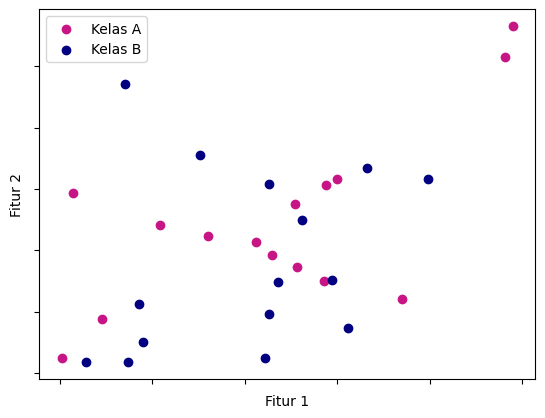

In [19]:
colors = {'class_a': 'MediumVioletRed', 'class_b': 'Navy'}

gb = df_label.groupby('Label')
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

## 6. Langkah 5 — Model Multinomial Naive Bayes

Model Multinomial dipakai hanya untuk pembelajaran. Model ini sejatinya diperuntukkan bagi fitur diskrit, bukan data kontinu.

In [20]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

mnb.fit(X_train, y_train)
acc_train = accuracy_score(y_train, mnb.predict(X_train))
acc_test = accuracy_score(y_test, mnb.predict(X_test))

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.6190476190476191
Hasil akurasi data test: 0.5555555555555556


## 7. Langkah 6 — Model Gaussian Naive Bayes

Model Gaussian lebih sesuai untuk data kontinu karena memakai distribusi normal.

In [21]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

acc_train_gnb = accuracy_score(y_train, gnb.predict(X_train))
acc_test_gnb = accuracy_score(y_test, gnb.predict(X_test))

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.6190476190476191
Hasil akurasi data test (Gaussian): 0.3333333333333333


## 8. Kesimpulan Praktikum 2

Model Gaussian dan Multinomial menghasilkan akurasi yang berbeda pada data kontinu. Secara teoritis, Gaussian lebih tepat untuk data kontinu, sedangkan Multinomial lebih tepat untuk data hitungan seperti teks.